# Image Manipulation

University Python exercises using NumPy and Matplotlib. Run the cells in order from this folder.

## Load and display the image

Read the supplied RGB JPEG and display it.

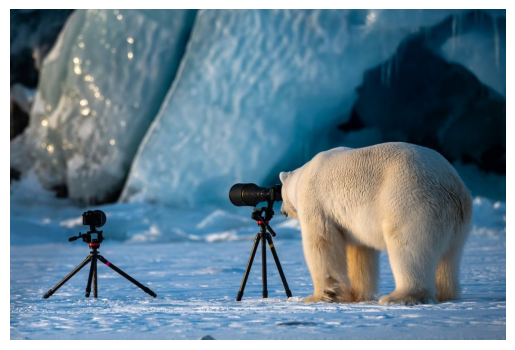

In [ ]:
import matplotlib.image as mpimg

img = mpimg.imread("polarbear.jpg")

import matplotlib.pyplot as plt

plt.imshow(img) 
plt.axis('off')
plt.show()


## Enhance the blue channel

Multiply the blue channel by 1.8, clip values to [0, 255], and convert back to uint8.

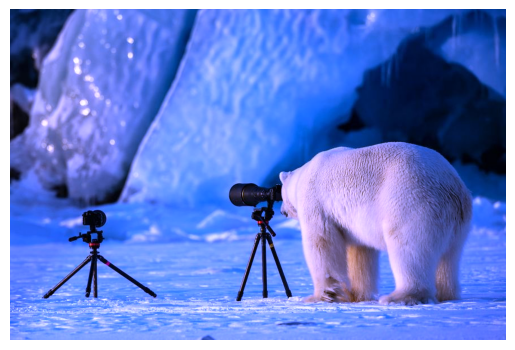

In [24]:
import numpy as np

def enhanceColor(img, factor, channel):
    imgB = np.float32(img.copy()) # Work on a floating-point copy to preserve the input.   
    imgB[:, :, channel] *= factor # Scale only the selected channel.

    imgB = np.clip(imgB, 0, 255) 
    imgB = np.uint8(imgB) 

    return imgB

plt.imshow(enhanceColor(img, 1.8, 2)) 
plt.axis('off')
plt.show()


## Mosaic effect

Replace each selected block with its central pixel color. Smaller windows preserve more detail; larger windows produce a stronger mosaic effect.

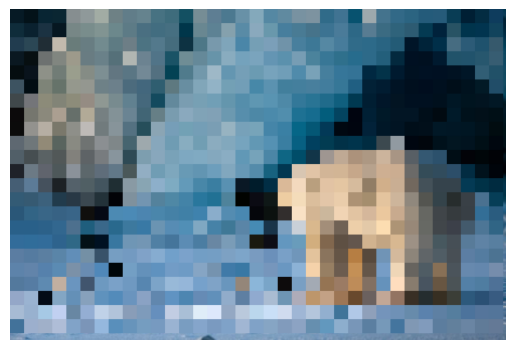

'\nAs W decreases, each mosaic block becomes smaller.\nTherefore, more blocks are needed to cover the image, making it look more detailed.\n'

In [ ]:
def imagemMosaico(img, W): # W is the block width used in this example.
    imgM = img.copy()
    halfW = int(np.floor(W / 2))

    for i in range(halfW, img.shape[0], W): 
        for j in range(halfW, img.shape[1], W): 

            row_start = max(0, i - halfW)
            row_end = min(img.shape[0], i + halfW + 1)

            col_start = max(0, j - halfW)
            col_end = min(img.shape[1], j + halfW + 1)

            imgM[row_start:row_end, col_start:col_end, :] = img[i, j, :]

    return imgM
            

plt.imshow(imagemMosaico(img, 25)) 
plt.axis('off')
plt.show()


## Grayscale conversion

Apply the original weighted RGB sum: 0.2978 R + 0.5870 G + 0.1140 B. The supplied coefficients are preserved.

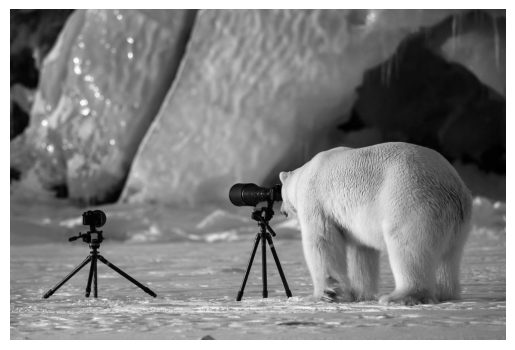

In [29]:
def color2gray(imgB):
    imgG = 0.2978 * imgB[:, :, 0] + 0.5870 * imgB[:, :, 1] + 0.1140 * imgB[:, :, 2]
    imgG = np.uint8(imgG)

    return imgG
                
    
plt.imshow(color2gray(enhanceColor(img, 1.8, 2)), cmap = "gray") 
plt.axis('off')
plt.show()


## Binary thresholding

Assign 255 to values at or above 85 and 0 otherwise. Increasing the threshold generally reduces the number of white pixels.

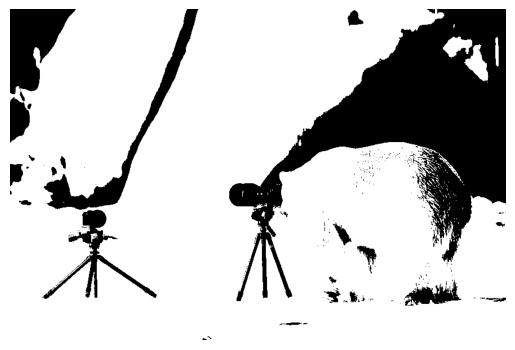

' \nhigher thresold = less white pixels\nlower thresold = more white pixels\n'

In [38]:
def imagemBin(imgG, threshold):
    imgBin = np.where(imgG >= threshold, 255, 0) 
    
    return imgBin

plt.imshow(imagemBin(color2gray(enhanceColor(img, 1.8, 2)), 85), cmap = "gray")
plt.axis('off')
plt.show()


## Contour extraction

Mark differences between neighboring pixels. The original boundary behavior is documented in REVIEW_NOTES.md.

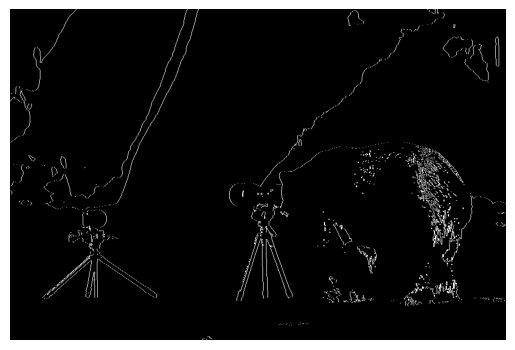

In [ ]:
def imagemCont(imgBin):
    imgCont = np.zeros_like(imgBin) # Initialize a black contour image.

    # Compare horizontal and vertical neighbors.
    for i in range(imgBin.shape[0]):
        for j in range(1, imgBin.shape[1]):
            if imgBin[i, j] != imgBin[i, j-1]: 
                imgCont[i, j] = 255
            if imgBin[i, j] != imgBin[i-1, j]: 
                imgCont[i, j] = 255
    return imgCont

plt.imshow(imagemCont(imagemBin(color2gray(enhanceColor(img, 1.8, 2)), 85)), cmap="gray")
plt.axis('off')
plt.show()


## BMP export and file sizes

Save the contour image and compare file sizes. The JPEG input and BMP output contain different images; this is not a controlled compression comparison.

In [52]:
imgCont = imagemCont(imagemBin(color2gray(enhanceColor(img, 1.8, 2)), 85))

mpimg.imsave("polarbear_contour.bmp", imgCont, cmap="gray")

import os

print(os.path.getsize("polarbear.jpg"))
print(os.path.getsize("polarbear_contour.bmp"))

print("JPEG size:", os.path.getsize("polarbear.jpg") / 1024, "KB")
print("BMP size:", os.path.getsize("polarbear_contour.bmp") / 1024, "KB")


73698
2066294
JPEG size: 71.970703125 KB
BMP size: 2017.865234375 KB


'  \nJPEG → compressed format\nBMP  → much less compressed / often uncompressed\n'